In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Load Data

In [2]:

url = f"https://drive.google.com/uc?id=1h5zbQyjm5F1iMufaU9QIh2aLBo-i-zP-"

df = pd.read_csv(url)

# 1. Data Understanding



In [3]:
# Display the number of rows and columns

df.shape

(16411, 7)

In [4]:
# Display column count, non-null counts, and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16411 entries, 0 to 16410
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   crop ID         16411 non-null  object 
 1   soil_type       16411 non-null  object 
 2   Seedling Stage  16411 non-null  object 
 3   MOI             16411 non-null  int64  
 4   temp            16411 non-null  int64  
 5   humidity        16411 non-null  float64
 6   result          16411 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 897.6+ KB


In [5]:
for col in df.columns:
    print(f"Column '{col}':")
    print(df[col].unique())
    print("\n" + "-"*30 + "\n")

Column 'crop ID':
['Wheat' 'Potato' 'Carrot' 'Tomato' 'Chilli']

------------------------------

Column 'soil_type':
['Black Soil' 'Alluvial Soil' 'Sandy Soil' 'Red Soil' 'Clay Soil'
 'Loam Soil' 'Chalky Soil']

------------------------------

Column 'Seedling Stage':
['Germination' 'Seedling Stage'
 'Vegetative Growth / Root or Tuber Development' 'Flowering' 'Pollination'
 'Fruit/Grain/Bulb Formation' 'Maturation' 'Harvest']

------------------------------

Column 'MOI':
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100]

------------------------------

Column 'temp':
[25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 2

In [6]:
print("Unique Values in Each Column:")
for col in df.columns:
    print(f"  {col}: {df[col].nunique()} unique")

Unique Values in Each Column:
  crop ID: 5 unique
  soil_type: 7 unique
  Seedling Stage: 8 unique
  MOI: 100 unique
  temp: 34 unique
  humidity: 106 unique
  result: 3 unique


In [7]:
# Display descriptive statistics for numerical columns

df.describe()

,MOI,temp,humidity,result
count,16411.000000,16411.000000,16411.000000,16411.000000
mean,43.695387,28.832612,63.487752,0.516178
std,27.160264,9.701465,22.630965,0.621691
min,1.000000,13.000000,15.000000,0.000000
25%,21.000000,20.000000,44.000000,0.000000
50%,41.000000,28.000000,69.200000,0.000000
75%,64.000000,37.000000,84.000000,1.000000
max,100.000000,46.000000,91.000000,2.000000


# 2. Preprocessing

## 2.1 Missing Values

In [8]:
# Identify missing values

missing = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percentage": round(df.isnull().mean()*100,2)
})

display(missing)

,Missing,Percentage
crop ID,0,0.0
soil_type,0,0.0
Seedling Stage,0,0.0
MOI,0,0.0
temp,0,0.0
humidity,0,0.0
result,0,0.0


## 2.2 Duplicate Data

In [9]:
# Count duplicate rows

df.duplicated().sum()

np.int64(128)

There are 128 duplicate rows. Mention in the report that duplicates may affect machine learning results.

In [10]:
# Display 10 duplicate rows

display(df[df.duplicated(keep=False)].sort_values(df.columns.tolist()).head(10))

,crop ID,soil_type,Seedling Stage,MOI,temp,humidity,result
11924,Carrot,Sandy Soil,Flowering,1,24,80.0,0
12249,Carrot,Sandy Soil,Flowering,1,24,80.0,0
11925,Carrot,Sandy Soil,Flowering,2,23,81.0,0
12250,Carrot,Sandy Soil,Flowering,2,23,81.0,0
11926,Carrot,Sandy Soil,Flowering,3,22,82.0,0
12251,Carrot,Sandy Soil,Flowering,3,22,82.0,0
11927,Carrot,Sandy Soil,Flowering,4,21,83.0,0
12252,Carrot,Sandy Soil,Flowering,4,21,83.0,0
11928,Carrot,Sandy Soil,Flowering,5,20,84.0,0
12253,Carrot,Sandy Soil,Flowering,5,20,84.0,0


Since there are duplicate rows (e.g., ID 12249 is a duplicate of ID 11924), they need to be handled before analysis.

In [11]:
# Remove duplicate rows

df = df.drop_duplicates().reset_index(drop=True)

In [12]:
# Check dataset dimensions after removing duplicates

df.shape

(16283, 7)

## 2.3 Outlier Detection
An outlier is a value that differs significantly from the other data values.

For example, in (2, 5, 3, 1, 4, 7, 4, 2, 80, 5, 3, 1), 80 is an outlier.

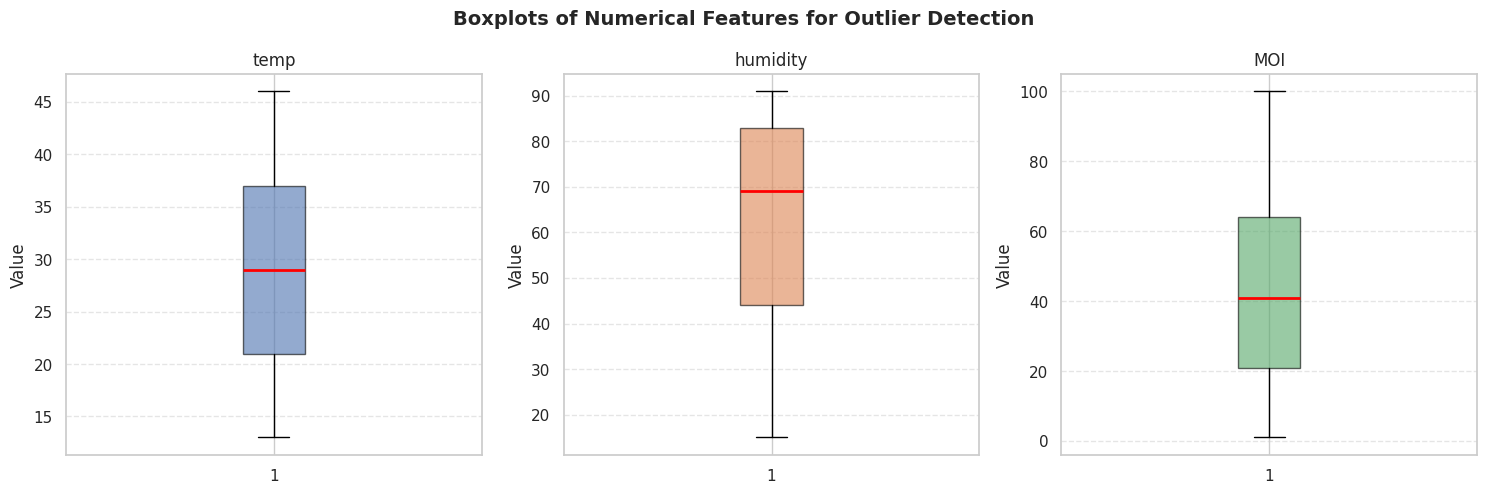

Outlier Analysis (IQR Method):
--------------------------------------------------
  temp      :    0 outliers (0.00%) | Range valid: [-3.0, 61.0]
  humidity  :    0 outliers (0.00%) | Range valid: [-14.5, 141.5]
  MOI       :    0 outliers (0.00%) | Range valid: [-43.5, 128.5]


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Boxplots of Numerical Features for Outlier Detection', fontsize=14, fontweight='bold')

fitur_numerik = ['temp', 'humidity', 'MOI']

colors = ['#4C72B0', '#DD8452', '#55A868']
for i, (col, color) in enumerate(zip(fitur_numerik, colors)):
    axes[i].boxplot(df[col], patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.6),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(f'{col}', fontsize=12)
    axes[i].set_ylabel('Value')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Count outlierss using the IQR method
print("Outlier Analysis (IQR Method):")
print("-" * 50)
for col in fitur_numerik:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    pct = n_outliers / len(df) * 100
    print(f"  {col:10s}: {n_outliers:4d} outliers ({pct:.2f}%) | Range valid: [{lower:.1f}, {upper:.1f}]")

Conclusion: No removal is needed because there are no outliers.s

## 2.4 Encoding

In [14]:
# Analyze feature types for encoding
encoding_analysis = pd.DataFrame({
    'Feature': ['crop ID', 'soil_type', 'Seedling Stage'],
    'Sample Categories': [
        ', '.join(map(str, df['crop ID'].unique()[:5])),
        ', '.join(map(str, df['soil_type'].unique()[:5])),
        ', '.join(map(str, df['Seedling Stage'].unique()[:5]))
    ]
})

encoding_analysis

,Feature,Sample Categories
0,crop ID,"Wheat, Potato, Carrot, Tomato, Chilli"
1,soil_type,"Black Soil, Alluvial Soil, Sandy Soil, Red Soi..."
2,Seedling Stage,"Germination, Seedling Stage, Vegetative Growth..."




**Reasons for Choosing the Encoding Methods:**
- **`crop ID`** (Wheat, Potato, etc.) → **One-Hot Encoding (OHE)** because it is a nominal categorical variable with no order. Label Encoding may cause the model to assume an ordinal relationship between crops (e.g., Wheat > Potato), although no such relationship exists.
- **`soil_type`** (7 soil types) → **One-Hot Encoding (OHE)** because it is also a nominal category with no order. OHE represents each soil type independently without implying a greater or smaller value.
- **`Seedling Stage`** (8 growth stages) → **Label Encoding** — these stages have a **logical order** (Germination → Harvest), making Label Encoding more suitable than OHE because the growth stages are ordinal.


*OHE (One-Hot Encoding) does not represent an order, such as 1 being greater than 0. Ordinal encoding, on the other hand, represents ordered values.*

In [15]:
df_encoded = df.copy()

# Apply label encoding to Seedling Stage
le_stage = LabelEncoder()
df_encoded['Seedling Stage'] = le_stage.fit_transform(df_encoded['Seedling Stage'])

# Apply one-hot encoding to crop ID and soil_type
df_encoded = pd.get_dummies(
    df_encoded,
    columns=['crop ID', 'soil_type'],
    drop_first=False
)

print("Shape after encoding:", df_encoded.shape)
display(df_encoded.head())

Shape after encoding: (16283, 17)


,Seedling Stage,MOI,temp,humidity,result,crop ID_Carrot,crop ID_Chilli,crop ID_Potato,crop ID_Tomato,crop ID_Wheat,soil_type_Alluvial Soil,soil_type_Black Soil,soil_type_Chalky Soil,soil_type_Clay Soil,soil_type_Loam Soil,soil_type_Red Soil,soil_type_Sandy Soil
0,2,1,25,80.0,1,False,False,False,False,True,False,True,False,False,False,False,False
1,2,2,26,77.0,1,False,False,False,False,True,False,True,False,False,False,False,False
2,2,3,27,74.0,1,False,False,False,False,True,False,True,False,False,False,False,False
3,2,4,28,71.0,1,False,False,False,False,True,False,True,False,False,False,False,False
4,2,5,29,68.0,1,False,False,False,False,True,False,True,False,False,False,False,False


## 2.5 Feature Identification

In [16]:
# Define the target
target = 'result'

# Use all columns except the target as features
fitur = [col for col in df.columns if col != target]

print("Features:", fitur)
print("Target:", target)

Features: ['crop ID', 'soil_type', 'Seedling Stage', 'MOI', 'temp', 'humidity']
Target: result


Download the Cleaned Dataset

In [17]:
df_encoded.to_csv('datasetcropclean.csv', index=False, sep=',')

# 3. Exploratory Data Analysis (EDA)

EDA is performed to understand data distribution patterns, relationships between variables, and important dataset characteristics before modeling.

## 3.1 Crop Type Distribution (crop ID)

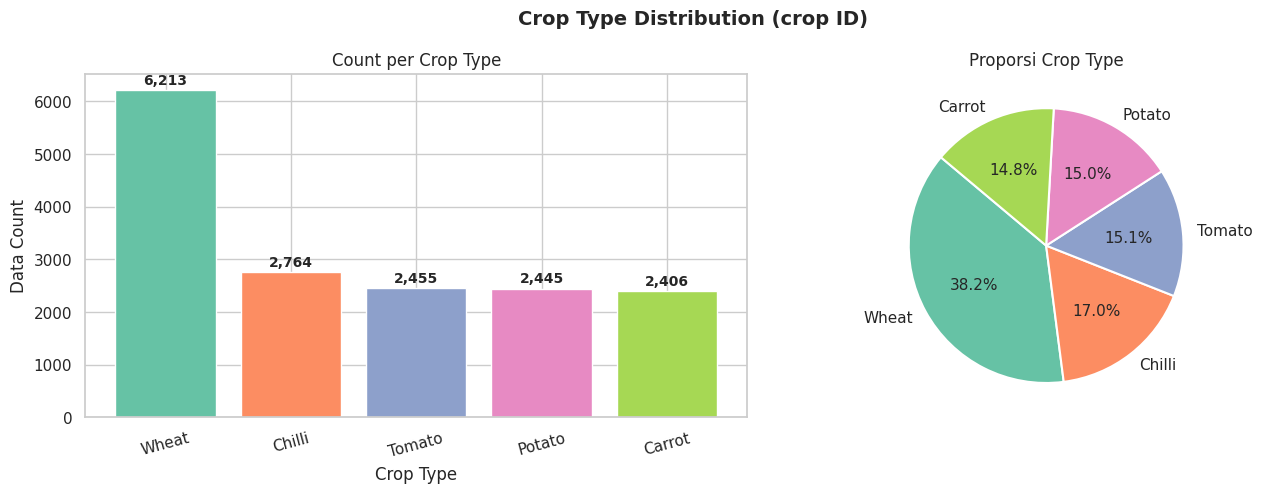


 Rincian Distribusi Crop Type:


,Count,Percentage (%)
crop ID,,
Wheat,6213,38.16
Chilli,2764,16.97
Tomato,2455,15.08
Potato,2445,15.02
Carrot,2406,14.78


In [18]:
crop_counts = df['crop ID'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Crop Type Distribution (crop ID)', fontsize=14, fontweight='bold')

# Bar chart
bars = axes[0].bar(crop_counts.index, crop_counts.values,
                   color=sns.color_palette('Set2', len(crop_counts)), edgecolor='white')
for bar, val in zip(bars, crop_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Count per Crop Type')
axes[0].set_xlabel('Crop Type')
axes[0].set_ylabel('Data Count')
axes[0].tick_params(axis='x', rotation=15)

# Pie chart
axes[1].pie(crop_counts.values, labels=crop_counts.index,
            autopct='%1.1f%%', colors=sns.color_palette('Set2', len(crop_counts)),
            startangle=140, wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Proporsi Crop Type')

plt.tight_layout()
plt.show()

print("\n Rincian Distribusi Crop Type:")
crop_table = pd.DataFrame({'Count': crop_counts, 'Percentage (%)': (crop_counts/len(df)*100).round(2)})
display(crop_table)

Include the visualization in the report and provide a conclusion.

The crop distribution is not perfectly balanced. **Wheat** dominates the dataset with a share of 38%, while Tomato, Carrot, and Potato each account for approximately 15%. Chilli is in the middle at 17%. This imbalance should be considered during modeling because the model may be biased toward the majority class.

## 3.2 Soil Type Distribution (soil_type)

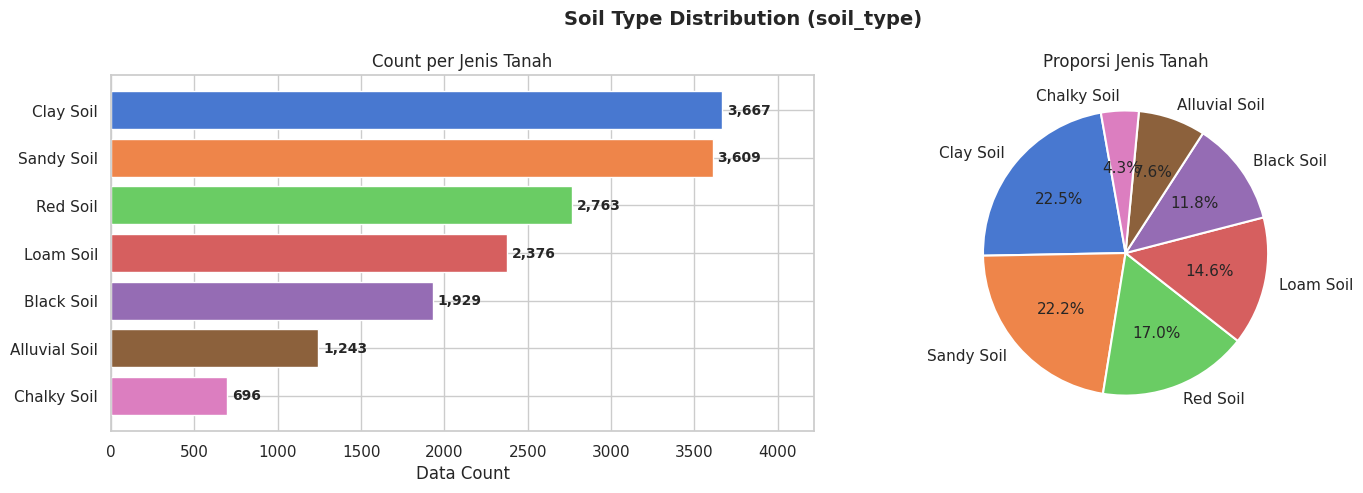


 Rincian Distribusi Jenis Tanah:


,Count,Percentage (%)
soil_type,,
Clay Soil,3667,22.52
Sandy Soil,3609,22.16
Red Soil,2763,16.97
Loam Soil,2376,14.59
Black Soil,1929,11.85
Alluvial Soil,1243,7.63
Chalky Soil,696,4.27


In [19]:
soil_counts = df['soil_type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Soil Type Distribution (soil_type)', fontsize=14, fontweight='bold')

# Horizontal bar chart
colors_soil = sns.color_palette('muted', len(soil_counts))
bars = axes[0].barh(soil_counts.index[::-1], soil_counts.values[::-1],
                    color=colors_soil[::-1], edgecolor='white')
for bar, val in zip(bars, soil_counts.values[::-1]):
    axes[0].text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
                 f'{val:,}', va='center', fontsize=10, fontweight='bold')
axes[0].set_title('Count per Jenis Tanah')
axes[0].set_xlabel('Data Count')
axes[0].set_xlim(0, soil_counts.max() * 1.15)

# Pie chart
axes[1].pie(soil_counts.values, labels=soil_counts.index,
            autopct='%1.1f%%', colors=colors_soil,
            startangle=100, wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Proporsi Jenis Tanah')

plt.tight_layout()
plt.show()

print("\n Rincian Distribusi Jenis Tanah:")
soil_table = pd.DataFrame({'Count': soil_counts, 'Percentage (%)': (soil_counts/len(df)*100).round(2)})
display(soil_table)

## 3.3 Seedling Stage Distribution



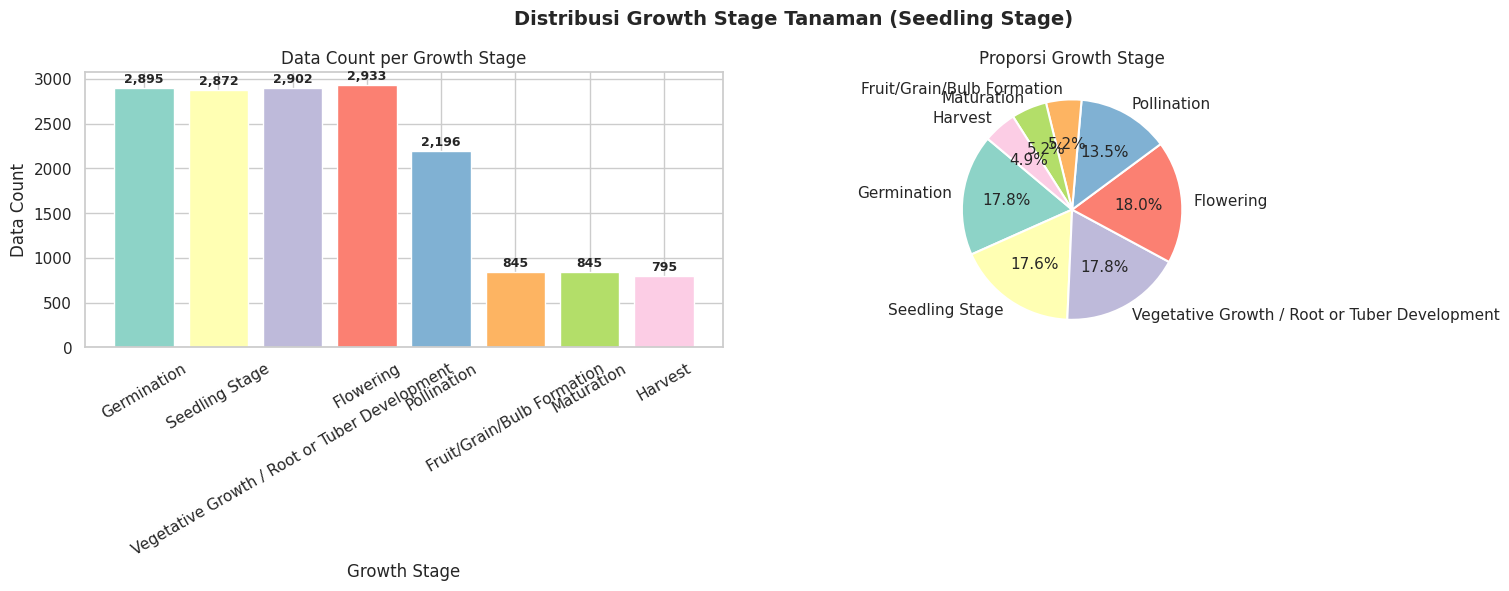


Seedling Stage Distribution Details:


,Growth Stage,Count,Percentage (%)
0,Germination,2895,17.78
1,Seedling Stage,2872,17.64
2,Vegetative Growth / Root or Tuber Development,2902,17.82
3,Flowering,2933,18.01
4,Pollination,2196,13.49
5,Fruit/Grain/Bulb Formation,845,5.19
6,Maturation,845,5.19
7,Harvest,795,4.88


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


stage_mapping = {
    1: 'Germination',
    2: 'Seedling Stage',
    3: 'Vegetative Growth / Root or Tuber Development',
    4: 'Flowering',
    5: 'Pollination',
    6: 'Fruit/Grain/Bulb Formation',
    7: 'Maturation',
    8: 'Harvest'
}

# Get unique stage names in the defined order
ordered_stage_names = [stage_mapping[i] for i in sorted(stage_mapping.keys())]

# Calculate counts and apply the defined order
stage_counts = df['Seedling Stage'].value_counts().reindex(ordered_stage_names)

# Replace missing counts with 0 and convert to integers
stage_counts = stage_counts.fillna(0).astype(int)

# Use the ordered stage counts as labels
stage_labels = stage_counts.index.tolist()

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Distribusi Growth Stage Tanaman (Seedling Stage)',
             fontsize=14, fontweight='bold')

# Bar chart
bars = axes[0].bar(
    stage_labels,
    stage_counts.values,
    color=sns.color_palette('Set3', len(stage_counts)),
    edgecolor='white'
)

for bar, val in zip(bars, stage_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 30,
        f'{val:,}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

axes[0].set_title('Data Count per Growth Stage')
axes[0].set_xlabel('Growth Stage')
axes[0].set_ylabel('Data Count')
axes[0].tick_params(axis='x', rotation=30)

# Pie chart
axes[1].pie(
    stage_counts.values,
    labels=stage_labels,
    autopct='%1.1f%%',
    colors=sns.color_palette('Set3', len(stage_counts)),
    startangle=140,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

axes[1].set_title('Proporsi Growth Stage')

plt.tight_layout()
plt.show()

# Distribution table
print("\nSeedling Stage Distribution Details:")

stage_table = pd.DataFrame({
    'Growth Stage': stage_labels,
    'Count': stage_counts.values,
    'Percentage (%)': (stage_counts.values / len(df) * 100).round(2)
})

display(stage_table)

## 3.3 Target Distribution (`result`)


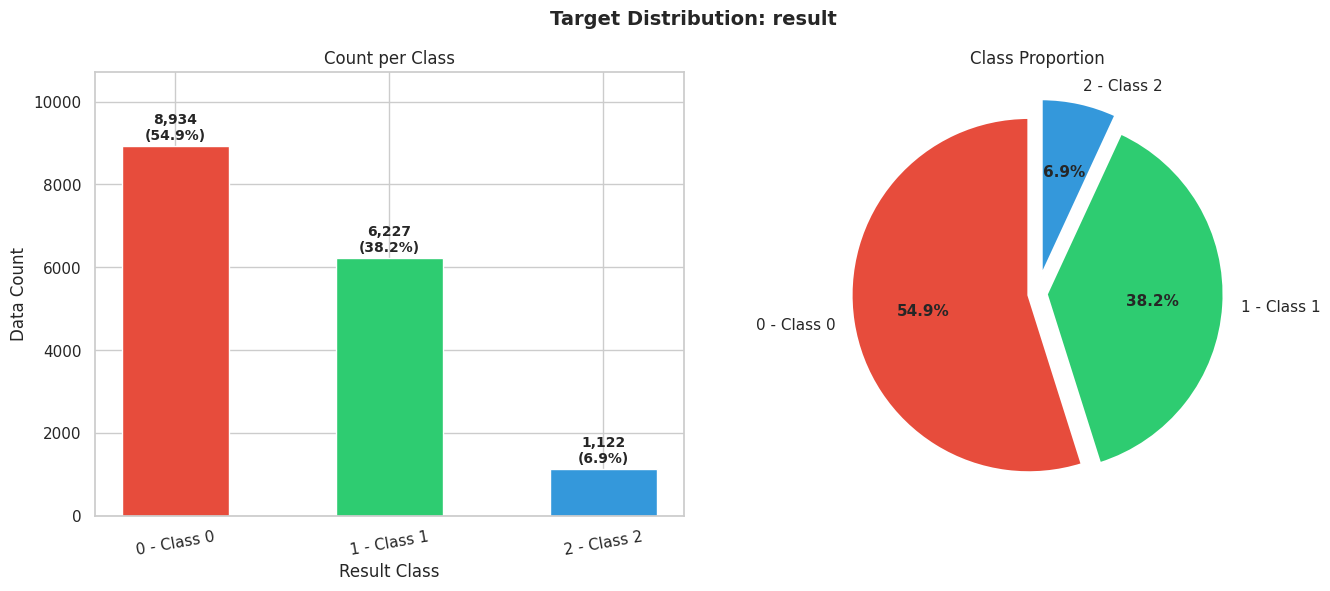


 Target Distribution Details:


,Class,Count,Percentage (%)
0,0 - Class 0,8934,54.87
1,1 - Class 1,6227,38.24
2,2 - Class 2,1122,6.89


In [21]:
result_map   = {0: '0 - Class 0', 1: '1 - Class 1', 2: '2 - Class 2'}
result_counts = df['result'].value_counts().sort_index()
result_labels = [result_map[i] for i in result_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Target Distribution: result', fontsize=14, fontweight='bold')

colors_result = ['#E74C3C', '#2ECC71', '#3498DB']

# Bar chart
bars = axes[0].bar(result_labels, result_counts.values,
                   color=colors_result, edgecolor='white', width=0.5)
for bar, val in zip(bars, result_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
                 f'{val:,}\n({val/len(df)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Count per Class')
axes[0].set_xlabel('Result Class')
axes[0].set_ylabel('Data Count')
axes[0].tick_params(axis='x', rotation=10)
axes[0].set_ylim(0, result_counts.max() * 1.2)

# Pie chart
wedges, texts, autotexts = axes[1].pie(
    result_counts.values, labels=result_labels,
    autopct='%1.1f%%', colors=colors_result,
    startangle=90, wedgeprops=dict(edgecolor='white', linewidth=2),
    explode=[0.05, 0.05, 0.1]
)
for autotext in autotexts:
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')
axes[1].set_title('Class Proportion')

plt.tight_layout()
plt.show()

print("\n Target Distribution Details:")
result_table = pd.DataFrame({
    'Class': result_labels,
    'Count': result_counts.values,
    'Percentage (%)': (result_counts.values / len(df) * 100).round(2)
})
display(result_table)

## 3.4 Numerical Feature Distribution

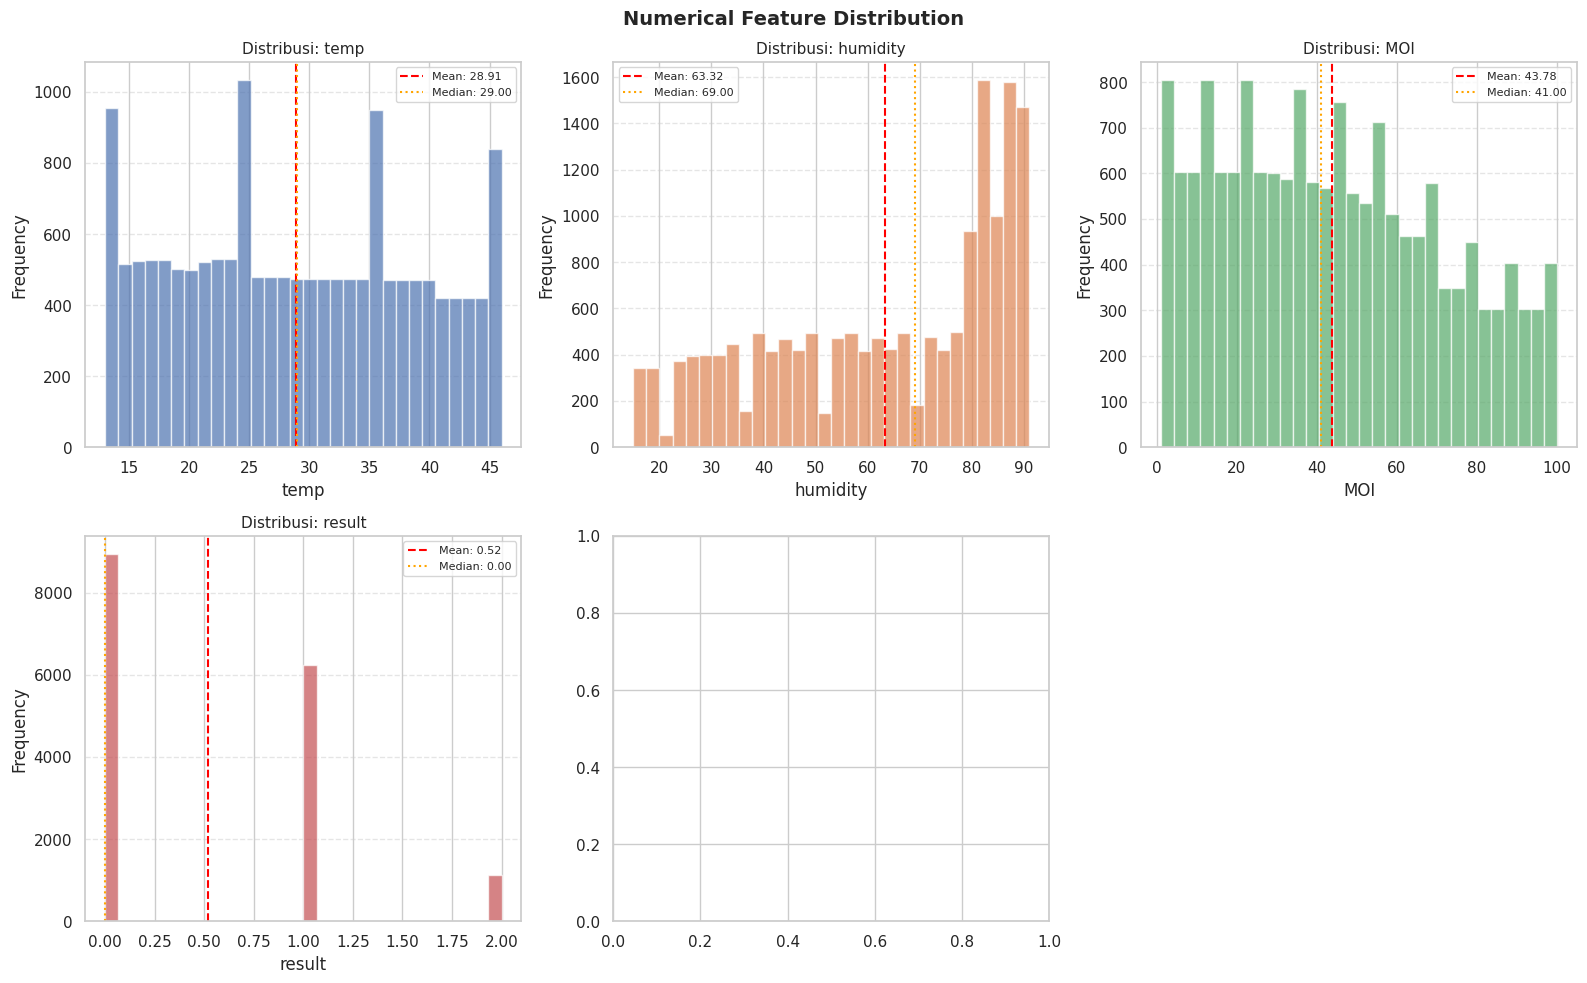

In [22]:

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Numerical Feature Distribution', fontsize=14, fontweight='bold')

numerik_all = fitur_numerik + [target]
colors_num  = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for i, (col, color) in enumerate(zip(numerik_all, colors_num)):
    row, col_idx = divmod(i, 3)
    ax = axes[row][col_idx]
    ax.hist(df[col], bins=30, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {df[col].mean():.2f}')
    ax.axvline(df[col].median(), color='orange', linestyle=':', linewidth=1.5, label=f'Median: {df[col].median():.2f}')
    ax.set_title(f'Distribusi: {col}', fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Hide the empty subplot
axes[1][2].set_visible(False)

plt.tight_layout()
plt.show()

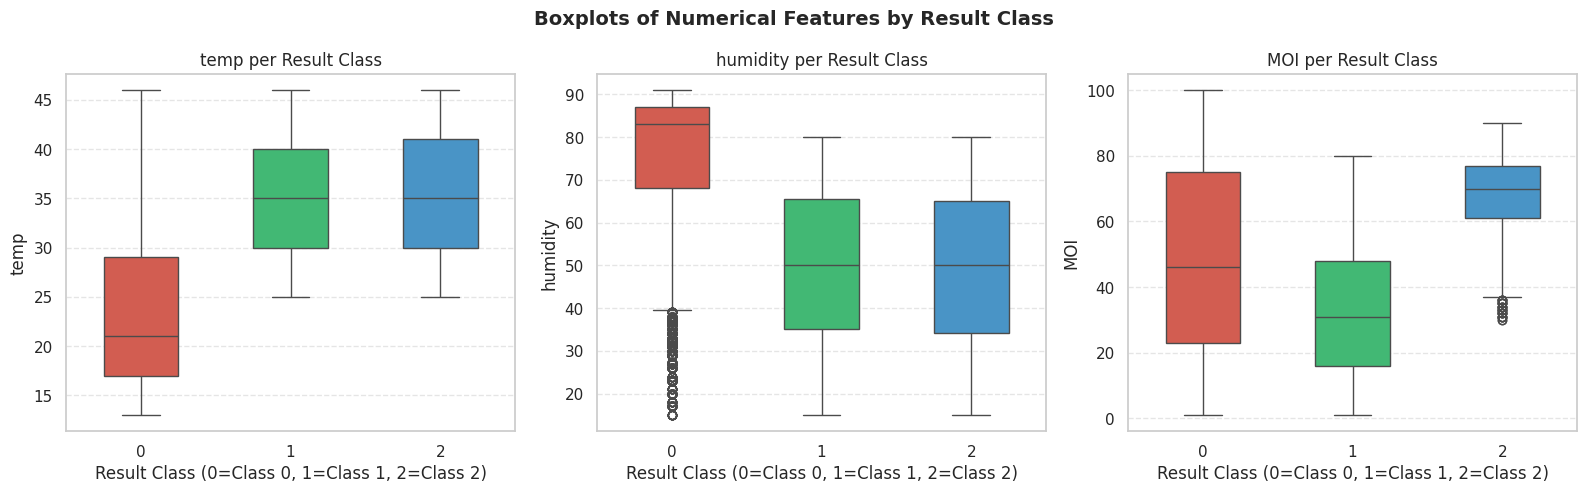


Rata-rata Fitur Numerik per Result Class:


,temp,humidity,MOI
result,,,
0,23.80,74.30,48.50
1,35.07,50.07,32.72
2,35.41,49.37,67.63


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Boxplots of Numerical Features by Result Class', fontsize=14, fontweight='bold')

palette_result = {'0': '#E74C3C', '1': '#2ECC71', '2': '#3498DB'}

for i, col in enumerate(fitur_numerik):
    sns.boxplot(data=df, x='result', y=col, ax=axes[i],
                palette=palette_result, width=0.5)
    axes[i].set_title(f'{col} per Result Class')
    axes[i].set_xlabel('Result Class (0=Class 0, 1=Class 1, 2=Class 2)')
    axes[i].set_ylabel(col)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Statistics by class
print("\nRata-rata Fitur Numerik per Result Class:")
display(df.groupby('result')[fitur_numerik].mean().round(2))

# 4. Correlation Analysis Between Variables

Correlation analysis uses Pearson Correlation to measure the strength of linear relationships between numerical features. Correlation values range from -1 (perfect negative correlation) to +1 (perfect positive correlation).

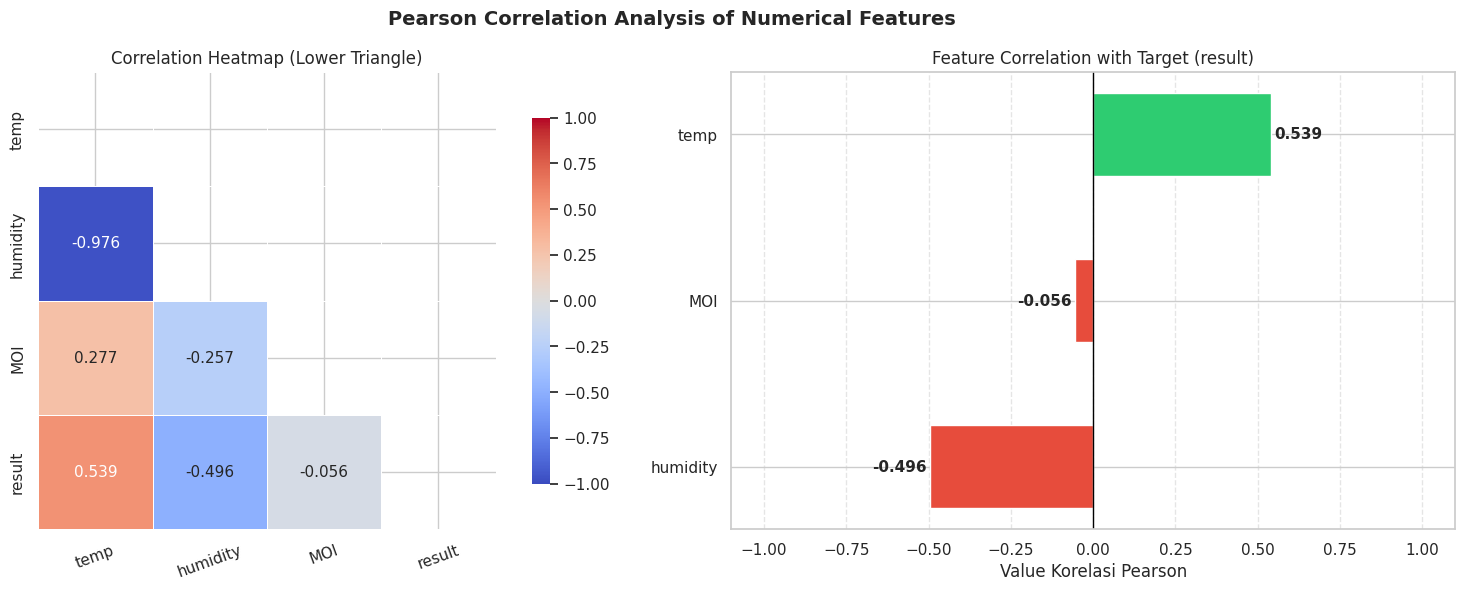


 Full Correlation Matrix:


,temp,humidity,MOI,result
temp,1.0000,-0.9761,0.2772,0.5390
humidity,-0.9761,1.0000,-0.2574,-0.4959
MOI,0.2772,-0.2574,1.0000,-0.0558
result,0.5390,-0.4959,-0.0558,1.0000


In [24]:
corr_matrix = df[fitur_numerik + [target]].corr(method='pearson')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Pearson Correlation Analysis of Numerical Features', fontsize=14, fontweight='bold')

# Full heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=axes[0],
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8},
            mask=mask)
axes[0].set_title('Correlation Heatmap (Lower Triangle)')
axes[0].tick_params(axis='x', rotation=20)

# Correlation with the target only
corr_target = corr_matrix['result'].drop('result').sort_values(ascending=True)
colors_bar = ['#E74C3C' if v < 0 else '#2ECC71' for v in corr_target.values]
bars = axes[1].barh(corr_target.index, corr_target.values,
                    color=colors_bar, edgecolor='white', height=0.5)
for bar, val in zip(bars, corr_target.values):
    x_pos = val + 0.01 if val >= 0 else val - 0.01
    ha = 'left' if val >= 0 else 'right'
    axes[1].text(x_pos, bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center', ha=ha, fontsize=11, fontweight='bold')
axes[1].axvline(x=0, color='black', linewidth=1)
axes[1].set_title('Feature Correlation with Target (result)')
axes[1].set_xlabel('Value Korelasi Pearson')
axes[1].set_xlim(-1.1, 1.1)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\n Full Correlation Matrix:")
display(corr_matrix.round(4))